# 04 · Business Insights

**Purpose:** answer the questions a customer-experience or social-media team would ask, and turn the answers into recommendations.

**Questions answered (Q1–Q17)**
- Which airlines are discussed most, and which are perceived best and worst?
- What are the main complaints overall and per airline, and who leads each operational category by count and by rate?
- Which tweets and sentiments get amplified?
- Are there real temporal patterns, or collection artefacts?

> **Net Sentiment Score = Positive % − Negative %** (a project-defined KPI for comparison, not an industry-standard metric).

> **Reading the results:** this is observational analysis of about one week of tweets. The findings describe what the dataset suggests; they do not prove causes.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.config import SENTIMENT_ORDER
from src.data import load_clean_tweets
from src.plotting import CATEGORICAL_COLORS, PRIMARY_COLOR, SENTIMENT_COLORS, apply_style, save_figure
from src.preprocessing import mask_user_handles

pd.set_option("display.max_colwidth", 140)
apply_style()

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [2]:
df = load_clean_tweets(parse_dates=True)
negative_df = df[df["airline_sentiment"] == "Negative"].copy()

# Tweets per airline, reused as the denominator for rate-based comparisons
airline_totals = df["airline"].value_counts()

print(f"Tweets analysed: {len(df):,} | Negative tweets: {len(negative_df):,} | Airlines: {df['airline'].nunique()}")

Tweets analysed: 14,481 | Negative tweets: 9,082 | Airlines: 6


### Airline Scorecard

One table that later questions draw from: volume, sentiment mix, Net Sentiment Score and average sentiment score for each airline.

In [3]:
scorecard = (
    df.groupby("airline")
    .agg(
        tweets=("tweet_id", "count"),
        positive_pct=("is_positive", "mean"),
        neutral_pct=("is_neutral", "mean"),
        negative_pct=("is_negative", "mean"),
        avg_sentiment_score=("sentiment_score", "mean"),
        total_retweets=("retweet_count", "sum"),
        avg_retweets=("retweet_count", "mean"),
    )
)
# Flags averaged = proportion; convert to percentages
for column in ["positive_pct", "neutral_pct", "negative_pct"]:
    scorecard[column] = scorecard[column] * 100

scorecard["net_sentiment_score"] = scorecard["positive_pct"] - scorecard["negative_pct"]
scorecard["share_of_discussion_pct"] = scorecard["tweets"] / scorecard["tweets"].sum() * 100
scorecard = scorecard.sort_values("net_sentiment_score", ascending=False)

scorecard.round(2)

,tweets,positive_pct,neutral_pct,negative_pct,avg_sentiment_score,total_retweets,avg_retweets,net_sentiment_score,share_of_discussion_pct
airline,,,,,,,,,
Virgin America,504,30.16,33.93,35.91,-0.06,26,0.05,-5.75,3.48
JetBlue,2218,24.48,32.55,42.97,-0.18,248,0.11,-18.49,15.32
Southwest,2420,23.55,27.44,49.01,-0.25,145,0.06,-25.45,16.71
United,3822,12.87,18.24,68.89,-0.56,421,0.11,-56.02,26.39
American,2604,11.75,16.59,71.66,-0.60,115,0.04,-59.91,17.98
US Airways,2913,9.23,13.08,77.69,-0.68,249,0.09,-68.45,20.12


## Q1. Which airline receives the most customer discussion?

In [4]:
most_discussed = scorecard["tweets"].idxmax()
print(f"Most discussed: {most_discussed} with {scorecard.loc[most_discussed, 'tweets']:,} tweets "
      f"({scorecard.loc[most_discussed, 'share_of_discussion_pct']:.2f}% of all tweets)")

scorecard[["tweets", "share_of_discussion_pct"]].sort_values("tweets", ascending=False).round(2)

Most discussed: United with 3,822 tweets (26.39% of all tweets)


,tweets,share_of_discussion_pct
airline,,
United,3822,26.39
US Airways,2913,20.12
American,2604,17.98
Southwest,2420,16.71
JetBlue,2218,15.32
Virgin America,504,3.48


**Answer:** **United** receives the most discussion (3,822 tweets, 26.39%), followed by US Airways (20.12%). High volume means high visibility. It does not by itself mean worse service, so perception is compared using percentages below.

## Q2–Q5. Which airlines lead and trail on sentiment?

- Q2: highest Positive %
- Q3: highest Negative %
- Q4: strongest Net Sentiment Score
- Q5: weakest Net Sentiment Score

In [5]:
answers = {
    "Q2 Highest Positive %": (scorecard["positive_pct"].idxmax(), f"{scorecard['positive_pct'].max():.2f}%"),
    "Q3 Highest Negative %": (scorecard["negative_pct"].idxmax(), f"{scorecard['negative_pct'].max():.2f}%"),
    "Q4 Strongest Net Sentiment Score": (scorecard["net_sentiment_score"].idxmax(), f"{scorecard['net_sentiment_score'].max():.2f}"),
    "Q5 Weakest Net Sentiment Score": (scorecard["net_sentiment_score"].idxmin(), f"{scorecard['net_sentiment_score'].min():.2f}"),
}
pd.DataFrame(answers, index=["airline", "value"]).T

,airline,value
Q2 Highest Positive %,Virgin America,30.16%
Q3 Highest Negative %,US Airways,77.69%
Q4 Strongest Net Sentiment Score,Virgin America,-5.75
Q5 Weakest Net Sentiment Score,US Airways,-68.45


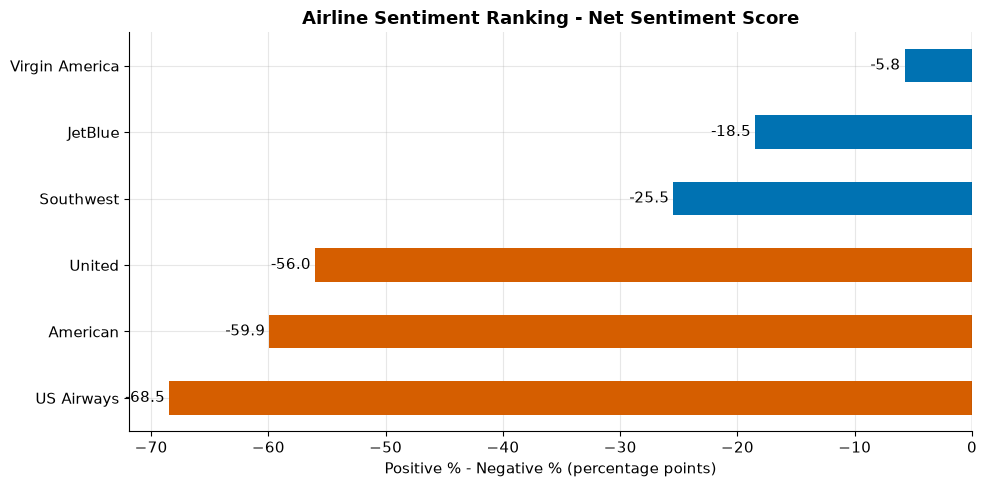

In [6]:
ranking = scorecard["net_sentiment_score"].sort_values()
colors = [SENTIMENT_COLORS["Negative"] if value < -50 else PRIMARY_COLOR for value in ranking]

ax = ranking.plot(kind="barh", color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Airline Sentiment Ranking - Net Sentiment Score")
ax.set_xlabel("Positive % - Negative % (percentage points)")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="{:.1f}", padding=3)
plt.tight_layout()
plt.show()

**Answers:**
- **Q2:** Virgin America has the highest Positive share (30.16%).
- **Q3:** US Airways has the highest Negative share (77.69%).
- **Q4:** Virgin America has the strongest Net Sentiment Score (−5.75).
- **Q5:** US Airways has the weakest Net Sentiment Score (−68.45).

The dataset suggests a clear split: US Airways, American and United (red bars) score below −50, while Southwest, JetBlue and Virgin America score between −26 and −6. Virgin America's lead rests on only 504 tweets. Notebook 05 checks how certain these rankings are.

## Q6. What are the most common customer complaints?

,negative_tweets,share_of_complaints_pct,cumulative_pct
negativereason,,,
Customer Service Issue,2883,31.74,31.74
Late Flight,1652,18.19,49.93
Can't Tell,1182,13.01,62.95
Cancelled Flight,831,9.15,72.10
Lost Luggage,718,7.91,80.00
Bad Flight,573,6.31,86.31
Flight Booking Problems,520,5.73,92.04
Flight Attendant Complaints,474,5.22,97.26
Long Lines,175,1.93,99.19


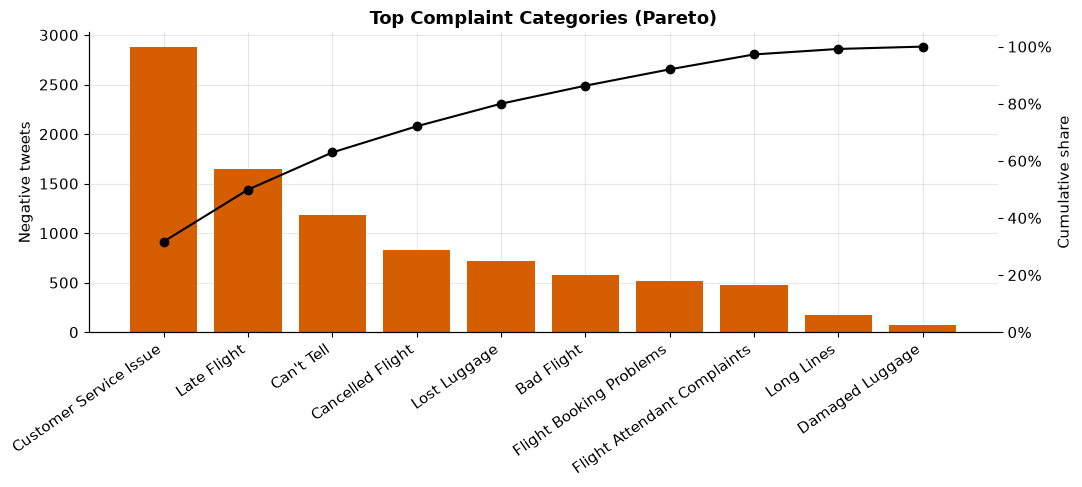

In [7]:
complaints = negative_df["negativereason"].value_counts().to_frame("negative_tweets")
complaints["share_of_complaints_pct"] = complaints["negative_tweets"] / complaints["negative_tweets"].sum() * 100
complaints["cumulative_pct"] = complaints["share_of_complaints_pct"].cumsum()
display(complaints.round(2))

# Pareto chart: bars = count, line = cumulative share
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(complaints.index, complaints["negative_tweets"], color=SENTIMENT_COLORS["Negative"])
ax1.set_ylabel("Negative tweets")
ax1.tick_params(axis="x", rotation=35)
plt.setp(ax1.get_xticklabels(), ha="right")
ax2 = ax1.twinx()
ax2.plot(complaints.index, complaints["cumulative_pct"], color="black", marker="o")
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylabel("Cumulative share")
ax2.grid(False)
ax1.set_title("Top Complaint Categories (Pareto)")
plt.tight_layout()
save_figure("complaint_pareto.png")
plt.show()

**Answer:** **Customer Service Issue** (31.74%) and **Late Flight** (18.19%) together make up about half of all complaints. Adding Cancelled Flight and Lost Luggage, the four operational categories explored below cover about 67% of complaints (Can't Tell is excluded from that figure because it has no actionable category).

## Q7. What is the most common complaint for each airline?

In [8]:
reason_by_airline = pd.crosstab(negative_df["airline"], negative_df["negativereason"])
reason_share = reason_by_airline.div(reason_by_airline.sum(axis=1), axis=0) * 100

top_complaint = pd.DataFrame({
    "top_complaint": reason_by_airline.idxmax(axis=1),
    "complaint_tweets": reason_by_airline.max(axis=1),
    "pct_of_airline_negative": reason_share.max(axis=1).round(2),
    "second_complaint": reason_by_airline.apply(lambda row: row.nlargest(2).index[1], axis=1),
})
top_complaint.sort_values("complaint_tweets", ascending=False)

,top_complaint,complaint_tweets,pct_of_airline_negative,second_complaint
airline,,,,
US Airways,Customer Service Issue,811,35.84,Late Flight
American,Customer Service Issue,741,39.71,Late Flight
United,Customer Service Issue,681,25.86,Late Flight
Southwest,Customer Service Issue,391,32.97,Cancelled Flight
JetBlue,Late Flight,269,28.23,Customer Service Issue
Virgin America,Customer Service Issue,60,33.15,Flight Booking Problems


**Answer:** Customer Service Issue is the #1 complaint for five of six airlines, with its highest share at American (39.71% of American's Negative tweets). JetBlue is the only airline where Late Flight ranks first.

## Q8–Q11. Which airline receives the most complaints in the key operational categories?

Two views are shown:
- **Raw count**: which airline has the most complaints of that type.
- **Rate per 100 tweets**: complaints of that type ÷ all tweets about the airline × 100. This controls for the fact that United gets roughly 7.6× more tweets than Virgin America.

In [9]:
key_reasons = ["Customer Service Issue", "Late Flight", "Cancelled Flight", "Lost Luggage"]

leader_rows = []
for reason in key_reasons:
    counts = negative_df[negative_df["negativereason"] == reason]["airline"].value_counts()
    rates = (counts / airline_totals * 100).dropna()
    leader_rows.append({
        "complaint": reason,
        "leader_by_count": counts.idxmax(),
        "count": int(counts.max()),
        "leader_by_rate": rates.idxmax(),
        "rate_per_100_tweets": round(rates.max(), 2),
    })

pd.DataFrame(leader_rows)

,complaint,leader_by_count,count,leader_by_rate,rate_per_100_tweets
0,Customer Service Issue,US Airways,811,American,28.46
1,Late Flight,United,525,US Airways,15.55
2,Cancelled Flight,American,230,American,8.83
3,Lost Luggage,United,269,United,7.04


negativereason,Customer Service Issue,Late Flight,Cancelled Flight,Lost Luggage
airline,,,,
American,28.46,9.06,8.83,5.49
US Airways,27.84,15.55,6.49,5.29
United,17.82,13.74,4.74,7.04
Southwest,16.16,6.28,6.69,3.72
Virgin America,11.90,3.37,3.57,0.99
JetBlue,8.97,12.13,2.30,2.57


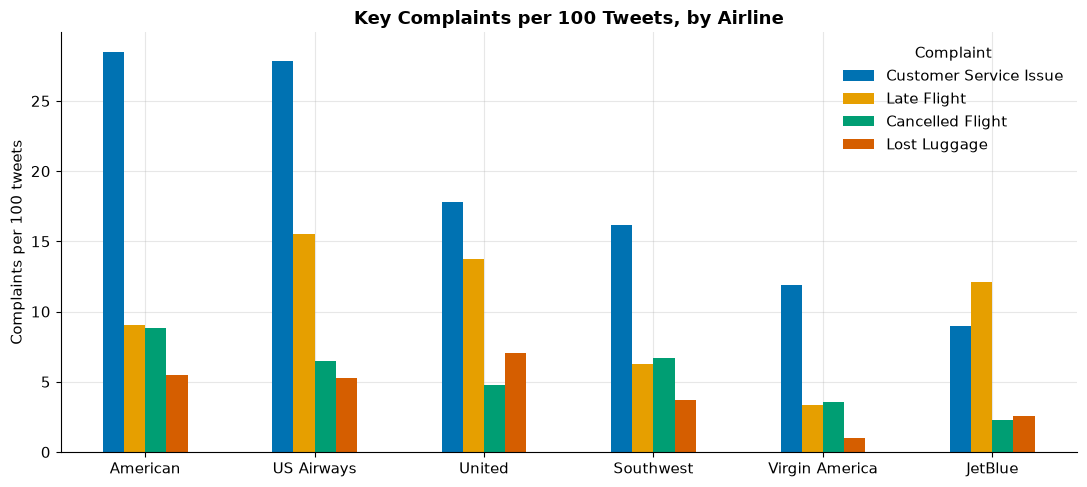

In [10]:
# Full rate table for the four categories
key_reason_rates = (
    reason_by_airline[key_reasons].div(airline_totals, axis=0) * 100
).round(2).sort_values("Customer Service Issue", ascending=False)
display(key_reason_rates)

ax = key_reason_rates.plot(kind="bar", figsize=(11, 5), color=CATEGORICAL_COLORS)
ax.set_title("Key Complaints per 100 Tweets, by Airline")
ax.set_xlabel("")
ax.set_ylabel("Complaints per 100 tweets")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Complaint")
plt.tight_layout()
plt.show()

**Answers:**

| Question | Most complaints (count) | Highest rate (per 100 tweets) |
|---|---|---|
| Q8 Customer Service Issue | US Airways (811) | American (28.46) |
| Q9 Late Flight | United (525) | US Airways (15.55) |
| Q10 Cancelled Flight | American (230) | American (8.83) |
| Q11 Lost Luggage | United (269) | United (7.04) |

Normalising changes two of the four answers. American generates a higher customer-service complaint rate than US Airways, and US Airways has a higher Late Flight rate than United. Cancelled Flight (American) and Lost Luggage (United) lead on both measures, so those are the most robust signals.

## Q12. Which sentiment category receives the highest average retweets?

In [11]:
retweets_by_sentiment = df.groupby("airline_sentiment")["retweet_count"].agg(
    average_retweets="mean",
    pct_retweeted=lambda s: (s > 0).mean() * 100,
    total_retweets="sum",
).reindex(SENTIMENT_ORDER)
retweets_by_sentiment.round(4)

,average_retweets,pct_retweeted,total_retweets
airline_sentiment,,,
Positive,0.0690,3.2161,161
Neutral,0.0613,3.0323,188
Negative,0.0941,6.5514,855


**Answer:** **Negative** tweets have the highest average retweets (0.0941) and the highest chance of being retweeted (6.55% vs about 3% for Positive and Neutral). The dataset suggests complaints travel further than praise, but retweets are rare overall.

## Q13. Which airline receives the highest average retweets?

In [12]:
retweets_by_airline = df.groupby("airline")["retweet_count"].agg(
    average_retweets="mean",
    median_retweets="median",
    pct_retweeted=lambda s: (s > 0).mean() * 100,
    max_retweets="max",
).sort_values("average_retweets", ascending=False)
retweets_by_airline.round(4)

,average_retweets,median_retweets,pct_retweeted,max_retweets
airline,,,,
JetBlue,0.1118,0.0,4.0577,31
United,0.1102,0.0,9.9163,7
US Airways,0.0855,0.0,4.0851,44
Southwest,0.0599,0.0,3.5537,22
Virgin America,0.0516,0.0,2.9762,4
American,0.0442,0.0,2.8418,5


**Answer:** **JetBlue** has the highest average (0.1118), narrowly ahead of United (0.1102). Notebook 03 (section 14) showed JetBlue's figure comes mostly from reactions to one viral "on fleek" post. United has by far the highest share of tweets retweeted at least once (9.92%), so **United is the most consistently amplified airline**.

## Q14. What are the most-retweeted negative tweets?

In [13]:
most_retweeted_negative = negative_df.nlargest(10, "retweet_count")[
    ["airline", "negativereason", "retweet_count", "tweet_date", "text"]
]
most_retweeted_negative.assign(text=most_retweeted_negative["text"].map(mask_user_handles))

,airline,negativereason,retweet_count,tweet_date,text
11594,US Airways,Late Flight,44,2015-02-17,"@USAirways 5 hr flight delay and a delay when we land . Is that even real life ? Get me off this plane , I wanna go home 👠👠👠 (3 heel cli..."
11580,US Airways,Can't Tell,32,2015-02-17,@USAirways of course never again tho . Thanks for tweetin ur concern but not Doin anythin to fix what happened. I'll choose wiser next time
7132,JetBlue,Can't Tell,31,2015-02-23,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY. RT @JetBlue: Our fleet's on fleek. http://t.co/Fd2TNYcTrB
7115,JetBlue,Can't Tell,22,2015-02-23,can you not? RT @JetBlue Our fleet's on fleek. http://t.co/413GiAL0yl
7027,JetBlue,Can't Tell,18,2015-02-23,"Just in case you needed confirmation that ""on fleek"" is dead &amp; gone. RT @JetBlue: Our fleet's on fleek. http://t.co/G4O6yX7TMJ"
4144,United,Flight Booking Problems,7,2015-02-17,@united But I got a bad exchange rate so want my money back. Please can you refund without penalty.
7134,JetBlue,Can't Tell,7,2015-02-23,"“@JetBlue: Our fleet's on fleek. http://t.co/Lv9HwQDK9A”\n\nCan't fly you anymore, we had a good run ✌️"
4127,United,Flight Booking Problems,5,2015-02-17,@united @user @user What kind of hypocrisy is that? Only Cancelled Flightling tickets with bad exchange rate if in your advantage #united
12525,American,Cancelled Flight,5,2015-02-23,@AmericanAir Cancelled Flight my flight saying it is cause of weather condition when it was the only flight that was Cancelled Flight
4122,United,Flight Booking Problems,4,2015-02-17,@united @user so why did you Cancelled Flight tickets for thousands of people when you didn't like the exchange rate? #doublestandards


**Answer:** The most-amplified complaints are two US Airways tweets on 17 Feb (44 and 32 retweets), one about a 5-hour delay. Three of the top five are "Can't Tell" reactions to the JetBlue post. A social-care team would review tweets like the US Airways ones first, since they combine a clear service failure with high visibility.

## Q15. Which dates and days have the highest negative sentiment volume?

In [14]:
negative_by_date = pd.DataFrame({
    "negative_tweets": negative_df.groupby(negative_df["tweet_date"].dt.date).size(),
    "all_tweets": df.groupby(df["tweet_date"].dt.date).size(),
})
negative_by_date["negative_pct"] = (negative_by_date["negative_tweets"] / negative_by_date["all_tweets"] * 100).round(2)
display(negative_by_date.sort_values("negative_tweets", ascending=False).head(5))

negative_by_day = negative_df["day_name"].value_counts().reindex(WEEKDAY_ORDER).to_frame("negative_tweets")
display(negative_by_day)

,negative_tweets,all_tweets,negative_pct
tweet_date,,,
2015-02-22,2261,3072,73.60
2015-02-23,1917,3026,63.35
2015-02-21,1049,1557,67.37
2015-02-17,838,1408,59.52
2015-02-20,834,1499,55.64


,negative_tweets
day_name,
Monday,1920
Tuesday,1531
Wednesday,736
Thursday,751
Friday,834
Saturday,1049
Sunday,2261


**Answer:** **22 February 2015 (Sunday)** has the most Negative tweets (2,261) and the highest Negative share (73.60%), followed by 23 February (1,917). This is partly a collection effect: American Airlines only enters the dataset on 22 Feb. Each weekday occurs only once or twice, so "Sunday" here means one specific Sunday.

## Q16. Are there meaningful temporal complaint patterns?

To separate a real change from the collection effect, the next cell compares complaint mix before and after 22 Feb **excluding American Airlines**, whose data only starts on that date.

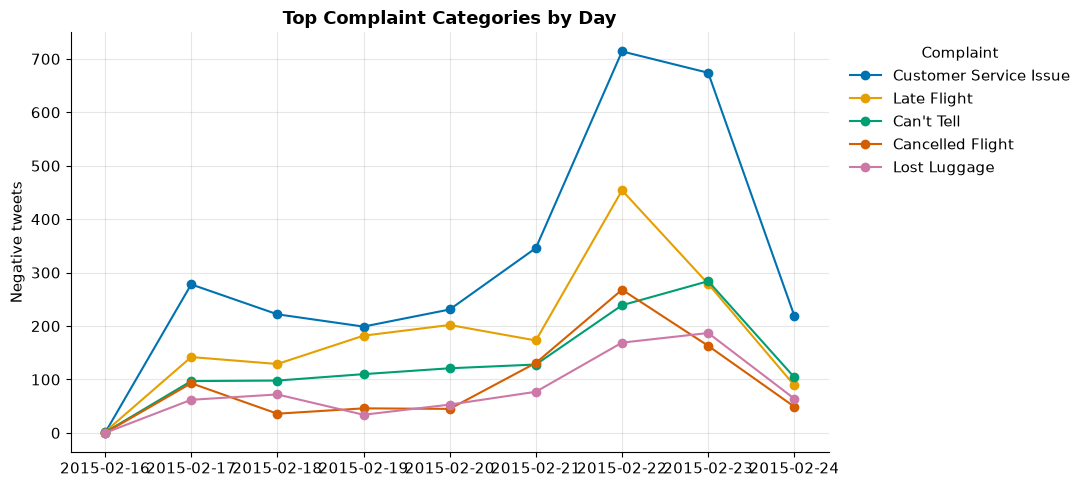

In [15]:
daily_complaints = pd.crosstab(negative_df["tweet_date"].dt.date, negative_df["negativereason"])
top_five_reasons = negative_df["negativereason"].value_counts().head(5).index

ax = daily_complaints[top_five_reasons].plot(marker="o", figsize=(11, 5))
ax.set_title("Top Complaint Categories by Day")
ax.set_xlabel("")
ax.set_ylabel("Negative tweets")
ax.legend(title="Complaint", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [16]:
# Like-for-like comparison: same five airlines in both periods
consistent_airlines = negative_df[negative_df["airline"] != "American"].copy()
consistent_airlines["period"] = np.where(consistent_airlines["tweet_date"] >= "2015-02-22", "22-24 Feb", "16-21 Feb")

period_mix = pd.crosstab(consistent_airlines["negativereason"], consistent_airlines["period"], normalize="columns") * 100
period_mix["change_pp"] = period_mix["22-24 Feb"] - period_mix["16-21 Feb"]
period_mix.sort_values("change_pp", ascending=False).round(2)

period,16-21 Feb,22-24 Feb,change_pp
negativereason,,,
Lost Luggage,7.06,9.24,2.18
Can't Tell,13.19,14.49,1.31
Flight Attendant Complaints,5.28,5.72,0.44
Cancelled Flight,8.34,8.31,-0.03
Long Lines,2.00,1.96,-0.03
Damaged Luggage,0.90,0.80,-0.11
Late Flight,19.70,19.51,-0.19
Bad Flight,7.15,6.38,-0.77
Flight Booking Problems,6.08,4.75,-1.33


**Answer:** Excluding American, the complaint mix is stable. No category moves by more than about 2.2 percentage points. Lost Luggage gains the most share (+2.18 pp) and Customer Service Issue loses the most (−1.48 pp). The large 22–23 Feb volume spike is therefore mostly **more tweets**, not a different kind of complaint. The dataset covers about 8 days, so these are **short-window shifts, not trends**. There is not enough history to establish seasonality or to forecast.

## Q17. Comparing airline perception with percentages rather than raw counts

In [17]:
raw_rank = df[df["airline_sentiment"] == "Negative"]["airline"].value_counts().rank(ascending=False).astype(int)
pct_rank = scorecard["negative_pct"].rank(ascending=False).astype(int)

comparison = pd.DataFrame({
    "negative_tweets": negative_df["airline"].value_counts(),
    "rank_by_count": raw_rank,
    "negative_pct": scorecard["negative_pct"].round(2),
    "rank_by_pct": pct_rank,
}).sort_values("rank_by_pct")
comparison

,negative_tweets,rank_by_count,negative_pct,rank_by_pct
airline,,,,
US Airways,2263,2,77.69,1
American,1866,3,71.66,2
United,2633,1,68.89,3
Southwest,1186,4,49.01,4
JetBlue,953,5,42.97,5
Virgin America,181,6,35.91,6


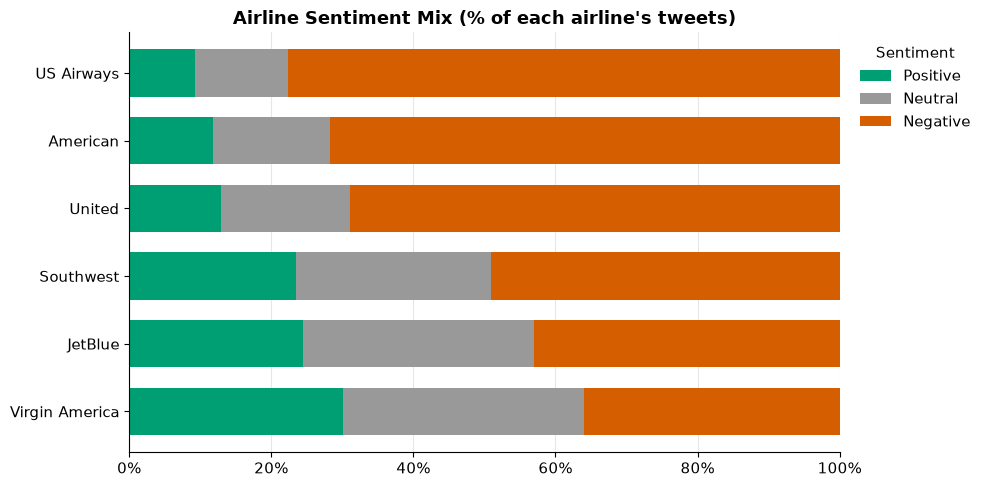

In [18]:
mix = scorecard[["positive_pct", "neutral_pct", "negative_pct"]].sort_values("negative_pct")
mix.columns = SENTIMENT_ORDER

ax = mix.plot(kind="barh", stacked=True, color=[SENTIMENT_COLORS[s] for s in SENTIMENT_ORDER], width=0.7)
ax.set_title("Airline Sentiment Mix (% of each airline's tweets)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.legend(title="Sentiment", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Answer:** By raw count, **United** has the most Negative tweets (2,633). By percentage, **US Airways** is worst (77.69%) and United drops to third. Southwest has more Negative tweets than JetBlue or Virgin America but still sits in the better-performing group. Percentages are the fairer basis for comparing airline perception. Counts are better for sizing the workload of a social-care team.

## Key Business Insights

In [19]:
best, worst = scorecard["net_sentiment_score"].idxmax(), scorecard["net_sentiment_score"].idxmin()
print(f"1. Discussion leader: {most_discussed} ({scorecard.loc[most_discussed, 'share_of_discussion_pct']:.2f}% of tweets).")
print(f"2. Net Sentiment Score ranges from {scorecard.loc[best, 'net_sentiment_score']:.2f} ({best}) "
      f"to {scorecard.loc[worst, 'net_sentiment_score']:.2f} ({worst}).")
print(f"3. Top complaint overall: {complaints.index[0]} ({complaints['share_of_complaints_pct'].iloc[0]:.2f}% of complaints).")
print(f"4. Negative tweets are retweeted {retweets_by_sentiment.loc['Negative', 'pct_retweeted']:.2f}% of the time "
      f"vs {retweets_by_sentiment.loc['Positive', 'pct_retweeted']:.2f}% for Positive.")

1. Discussion leader: United (26.39% of tweets).
2. Net Sentiment Score ranges from -5.75 (Virgin America) to -68.45 (US Airways).
3. Top complaint overall: Customer Service Issue (31.74% of complaints).
4. Negative tweets are retweeted 6.55% of the time vs 3.22% for Positive.


1. **Perception gap between two airline groups.** The dataset suggests US Airways (−68.45), American (−59.91) and United (−56.02) are perceived much more negatively than Southwest (−25.45), JetBlue (−18.49) and Virgin America (−5.75).
2. **Customer service is the main complaint driver.** Customer Service Issue is 31.74% of all complaints and the #1 complaint at five of six airlines. It is a service-recovery problem as much as an operational one.
3. **Each airline has a distinct operational weak spot.** American has the highest Cancelled Flight rate (8.83 per 100 tweets), United the highest Lost Luggage rate (7.04), and US Airways the highest Late Flight rate (15.55).
4. **Raw counts can mislead.** United leads Negative tweet counts but ranks third on Negative %. Customer-service complaint leadership moves from US Airways (count) to American (rate).
5. **Complaints are amplified more than praise.** Negative tweets are about twice as likely to be retweeted, so unresolved complaints carry reputational reach.
6. **Time patterns are largely a collection artifact.** The 22–23 Feb spike coincides with American entering the dataset. Short-window results should not be treated as trends.
7. **Data quality matters.** The source labelled JetBlue tweets as "Delta"; validation found and corrected this before analysis. One viral JetBlue post still distorts retweet metrics.

## Business Recommendations

These recommendations follow from the patterns in this dataset. Because the analysis is observational, each should be validated with operational data such as delay logs, baggage reports and contact-centre metrics.

1. **Prioritise customer-service recovery at American and US Airways.** They have the highest Customer Service Issue rates (28.46 and 27.84 per 100 tweets). Target faster first responses and clearer escalation paths on social channels.
2. **Target each airline's specific operational driver:**
   - American: cancellation communication and rebooking (highest Cancelled Flight rate)
   - United: baggage handling and tracking updates (highest Lost Luggage rate)
   - US Airways: proactive delay notifications (highest Late Flight rate)
3. **Triage by amplification.** Negative tweets are about twice as likely to be retweeted. Route Negative tweets that start gaining retweets to a senior social-care queue.
4. **Track Net Sentiment Score weekly alongside volume.** Report Positive %, Negative % and Net Sentiment Score together so that a rise in tweet volume is not mistaken for a drop in perception.
5. **Reduce "Can't Tell" complaints.** 13.01% of complaints have no usable category. Improving the complaint taxonomy or tagging process would make the data more actionable.
6. **Fix data collection before trend analysis.** Validate airline labels automatically (this dataset mislabelled JetBlue as Delta), collect all airlines over the same dates, and gather several months of data before drawing any trend or seasonality conclusions.